# 02 Split and Freeze Manifests

**Objective:** freeze deterministic train, validation, and untouched-test membership without copying any image or label files.

**Success criteria:** source policy is enforced, split paths do not overlap, manifests are hashed, and class balance is reviewed.


## Setup and upstream audit guard

Load the tracked config and require the latest data audit to be accepted. Create one new `split-manifests` artifact run.


In [1]:
# Purpose: initialize deterministic split generation from an accepted data audit.
# Inputs: tracked config and either the latest accepted audit artifact or its resolved run metadata.
# Guard: refuse to continue when the upstream audit is not accepted; never overwrite a prior split run.
# Output: a new run-scoped manifests workspace with reproducibility metadata.
from pathlib import Path
import sys

BOOTSTRAP_ROOT = Path.cwd().resolve()
if BOOTSTRAP_ROOT.name == "notebooks":
    BOOTSTRAP_ROOT = BOOTSTRAP_ROOT.parent
if str(BOOTSTRAP_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOTSTRAP_ROOT))

import pandas as pd
from IPython.display import display

from src.analysis.plot_utils import plot_split_balance
from src.artifacts import (
    create_run,
    find_latest_run,
    read_run_metadata,
    runtime_metadata,
    update_run_metadata,
    write_run_metadata,
)
from src.config import find_project_root, load_pipeline_config, resolve_project_path
from src.dataset.manifests import (
    build_split_assignments,
    collect_yolo_samples,
    manifest_pair_content_sha256,
    manifest_sha256,
    summarize_assignments,
    write_split_manifests,
)

V2_ROOT = find_project_root(BOOTSTRAP_ROOT)
CONFIG = load_pipeline_config(V2_ROOT)
DATASET_CONFIG = CONFIG["dataset"]
CLASS_NAMES = CONFIG["classes"]
SEED = int(DATASET_CONFIG["random_seed"])
AUDIT_RUN = find_latest_run(V2_ROOT, "data-audit", "run.yaml")
AUDIT_METADATA = read_run_metadata(AUDIT_RUN)
if AUDIT_METADATA.get("status") != "accepted":
    raise RuntimeError(f"Latest data audit is not accepted: {AUDIT_RUN.run_id}")
RUN = create_run(V2_ROOT, "split-manifests", "ppe-v2", SEED)
write_run_metadata(
    RUN,
    {
        "stage": "split-manifests",
        "status": "started",
        "seed": SEED,
        "source_audit_run": AUDIT_RUN.run_id,
        "runtime": runtime_metadata(V2_ROOT),
    },
)

WindowsPath('C:/Github/smart-factory-safety-monitoring-system/ppe-detection/v2_pipeline/artifacts/20260825T170142Z_split-manifests_ppe-v2_s42_027537d/run.yaml')

## Collect strict source pairs

**Input:** the same immutable source lanes accepted by Notebook 01.

**Expected result:** one compact count per source. Any mismatch or invalid label stops manifest creation.


In [2]:
# Purpose: rebuild strict image-label pair objects directly from immutable sources.
# Inputs: open-source, factory-source, and independent test-source directories.
# Guard: open source is optional/train-only, while factory and test lanes must be valid and non-empty.
# Output: validated sample lists and one bounded source-policy count table.
source_dirs = {
    name: resolve_project_path(V2_ROOT, configured_path)
    for name, configured_path in DATASET_CONFIG["input"].items()
}
collection_args = {
    "class_names": CLASS_NAMES,
    "image_extensions": DATASET_CONFIG["valid_image_extensions"],
    "allow_empty_labels": bool(DATASET_CONFIG["allow_empty_labels"]),
}
open_samples = collect_yolo_samples(
    source_dirs["open_source"], "open_source", required=False, **collection_args
)
factory_samples = collect_yolo_samples(
    source_dirs["factory_source"], "factory_source", **collection_args
)
test_samples = collect_yolo_samples(
    source_dirs["test_source"], "test_source", **collection_args
)
source_counts_df = pd.DataFrame(
    [
        {
            "source": "open_source",
            "valid_pairs": len(open_samples),
            "policy": "train only",
        },
        {
            "source": "factory_source",
            "valid_pairs": len(factory_samples),
            "policy": "train + val",
        },
        {
            "source": "test_source",
            "valid_pairs": len(test_samples),
            "policy": "final test only",
        },
    ]
)
display(source_counts_df)

,source,valid_pairs,policy
0,open_source,180,train only
1,factory_source,859,train + val
2,test_source,117,final test only


#### Observation

TODO after execution:

- Confirm pair counts match the accepted audit.
- Confirm `test_source` is independently supplied and non-empty.


## Freeze split membership

**Input:** source pairs, fixed seed, and factory train/validation ratios.

**Expected result:** three non-overlapping manifests, a compact split summary, and one class-balance figure. No image bytes are copied.


,split,num_images,num_objects,sources,num_person,num_helmet,num_vest,num_cleaning_coverall
0,train,867,5262,"factory_source, open_source",2316,1451,1390,105
1,val,172,989,factory_source,456,228,282,23
2,test,117,419,test_source,214,97,78,30


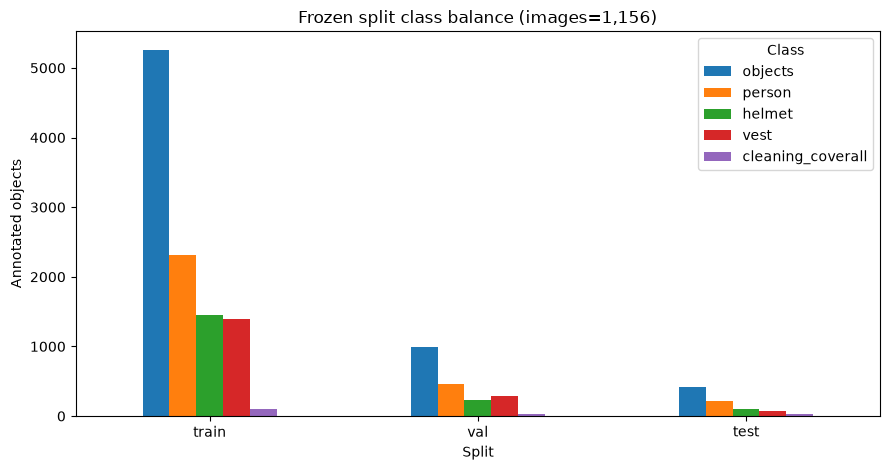

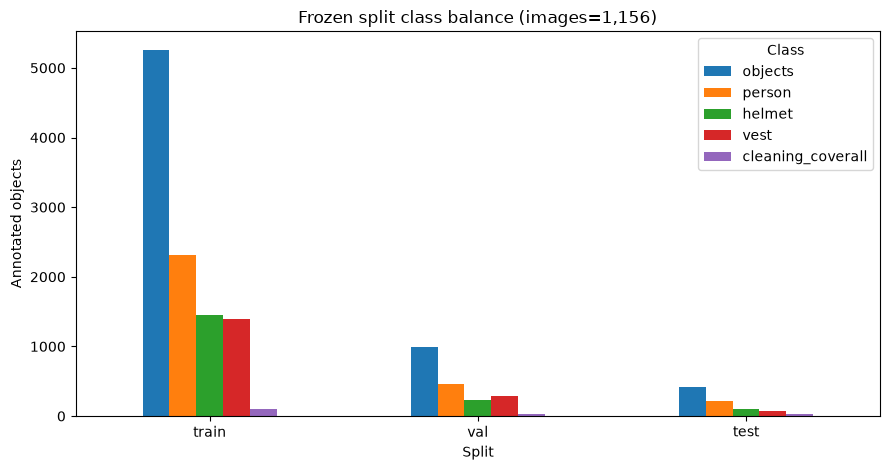

In [3]:
# Purpose: freeze train, validation, and test membership without copying image bytes.
# Inputs: source-aware samples, fixed seed, and configured factory split ratios.
# Guard: enforce stratification, source policy, required splits, and zero path overlap before writing.
# Output: absolute-path manifests, assignment CSV, split summary, and one class-balance figure.
split_config = DATASET_CONFIG["split"]
assignments_df, split_warnings_df = build_split_assignments(
    open_samples,
    factory_samples,
    test_samples,
    factory_train_ratio=float(split_config["factory_train"]),
    factory_val_ratio=float(split_config["factory_val"]),
    seed=SEED,
)
manifest_paths = write_split_manifests(assignments_df, RUN.manifests)
split_summary_df = summarize_assignments(assignments_df, CLASS_NAMES)
split_summary_path = RUN.csv / "split_summary.csv"
split_summary_df.to_csv(split_summary_path, index=False)
split_figure_path = RUN.figures / "frozen_split_class_balance.png"
split_figure = plot_split_balance(split_summary_df, split_figure_path)

display(split_summary_df)
display(split_figure)

#### Observation

TODO after execution:

- Record material train/validation imbalance.
- Confirm validation contains factory data only.
- Confirm test membership is untouched and excluded from all selection decisions.


## Review stratification limitations

Singleton class-presence groups cannot appear in both factory train and validation. Display and save warnings only when they exist.


In [4]:
# Purpose: make unavoidable stratification limitations visible without bloating normal runs.
# Inputs: singleton-group and missing-class-coverage warnings from split construction.
# Guard: warnings inform acceptance but never silently reshuffle the independent test set.
# Output: a short status or bounded warning table, with CSV persistence only when non-empty.
if split_warnings_df.empty:
    print("No stratification warnings.")
else:
    split_warnings_df.to_csv(RUN.csv / "split_warnings.csv", index=False)
    display(split_warnings_df.head(10))

,warning_type,details
0,stratification_singleton,1=0|2=1|3=1 has one factory sample and cannot ...


#### Observation

TODO after execution: state whether singleton groups or missing class coverage are acceptable for this experiment.


## Finalize hashes and split record

Manifest hashes freeze membership, while one test-pair fingerprint hashes the ordered test image and label bytes for the final integrity guard.


In [5]:
# Purpose: record exact membership and a tamper-evident test-data baseline.
# Inputs: the three frozen manifest files and ordered test image-label pairs.
# Guard: hash test content for later integrity checks; candidate/ablation stages receive no test manifest.
# Output: manifest hashes, test content fingerprint, summary references, and completed run metadata.
manifest_hashes = {
    name: manifest_sha256(path)
    for name, path in manifest_paths.items()
    if path.suffix == ".txt"
}
# Hash test image and label bytes once so the final notebook can detect source drift.
test_pair_content_sha256 = manifest_pair_content_sha256(manifest_paths["test"])
update_run_metadata(
    RUN,
    {
        "status": "completed",
        "manifests": {name: str(path) for name, path in manifest_paths.items()},
        "manifest_sha256": manifest_hashes,
        "test_pair_content_sha256": test_pair_content_sha256,
        "summary_csv": str(split_summary_path),
        "balance_figure": str(split_figure_path),
        "warning_count": int(len(split_warnings_df)),
    },
)
display(
    pd.DataFrame(
        [
            {"manifest": name, "sha256": digest}
            for name, digest in manifest_hashes.items()
        ]
    )
)
print(f"Split run: {RUN.run_id}")

,manifest,sha256
0,train_original,eec027ab132acc6f0de28873bc393a912d34b828c853fc...
1,val,4b979f22072df1c03ac62fd8a49b23f4ffefdad6f4a455...
2,test,7acfbda7581b8cdf0135d44e5599e19eb9975dc7953a36...


Split run: 20260825T170142Z_split-manifests_ppe-v2_s42_027537d


#### Observation

TODO after execution: record the accepted split run ID; downstream notebooks must reference this immutable run rather than regenerate membership silently.
